### Refined Question and Analysis Choices:

Central question: 
Are there shifts in invasive plant species presence before and after a prescribed burn takes place? 
Supporting questions: Are there changes in the number of invasive species observations before and after a prescribed burn? Are there changes in species richness of invasive species before and after a prescribed burn? Do different treatment types affect different invasive species?

Observations: 
Each observation in our data set is an invasive species plant observation that was observed within the polygon of a prescribed fire. Each row of observation includes basic information about the species observed, as well as information about the prescribed burn that its coordinate is contained within.

Variables: 
The variables we are using to analyze this question are “id” to derive observation counts from, “scientific_name” to derive species richness within a prescribed fire, “start_date” to label when a species is observed before a prescribed fire occurs, “end_date” to label when a species is observed after a prescribed fire occurs, “treatment_type” to observe if there are differences, and “acres_treated” to find the average number of species observations per hectare of prescribed burn. 

Units: 
There are no units for “id,” “scientific_name,” and “treatment_type.” “start_date” and “end_date” are formatted into dates, and also have no units. “acres_treated” has a unit of acres.
Intended comparison: We plan on comparing observation counts and species counts one year before and after the prescribed fire occurred to calculate if there is a change in invasive species presence.

Unresolved data limitations:
Because we are using citizen science for our observation data, our data may be subject to observation bias.
Another unresolved data limitation we have is figuring out what time range we should filter our observations to. The majority of our observations occurred starting 2019, so we aren’t sure if we should just filter out observations prior to 2019 and fires that occurred prior to 2020, or if we should still conduct our analysis spanning all years of our current dataset.

### Plots and Table for Week 3

In [27]:
# Prepare environment
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
fire_with_plants_joined = gpd.read_file(processed_fldr / "fire_with_plants_joined.gpkg")
invasives_within_year = gpd.read_file(processed_fldr / "invasives_within_year.gpkg")

invasives_within_year = gpd.GeoDataFrame(
    invasives_within_year,
    geometry="geometry",
    crs="EPSG:3310"
)

In [28]:
#AI consultation: how to add california outline to map
states = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
)
states = states.to_crs(fire_with_plants_joined.crs)
cal_outline = states.loc[states["NAME"] == "California"]

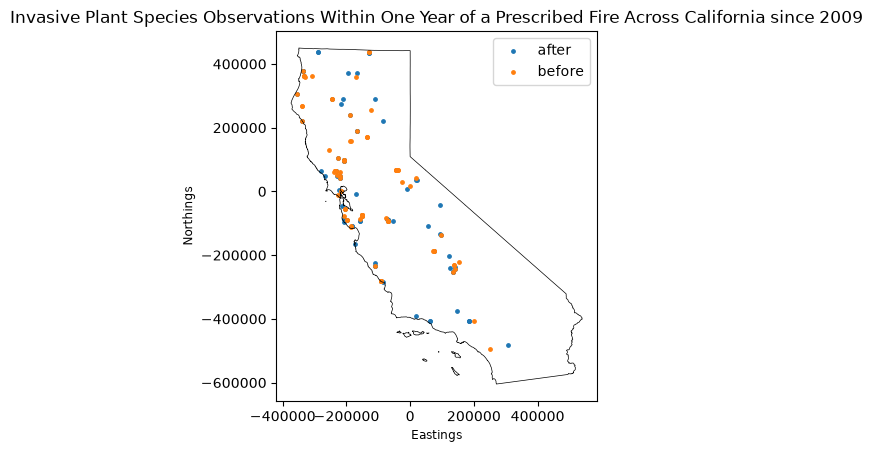

In [29]:
fig, ax = plt.subplots()

cal_outline.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.5
)

invasives_within_year.plot(
    markersize=6,
    column="before_after",
    legend=True,
    ax=ax
)

plt.title("Invasive Plant Species Observations Within One Year of a Prescribed Fire Across California since 2009");
plt.xlabel("Eastings");
plt.ylabel("Northings");

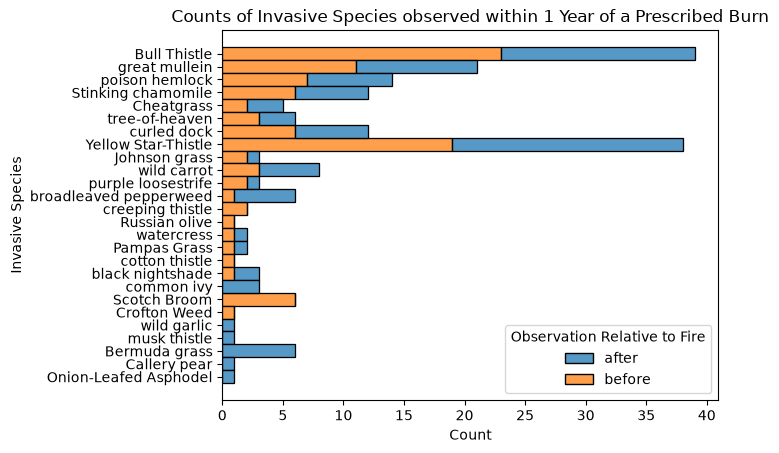

In [30]:
g = sns.histplot(data = invasives_within_year, y = "common_name", hue= "before_after", hue_order= ["after", "before"], multiple= "stack")

g.set(xlabel = "Count",
      ylabel = "Invasive Species",
      title = "Counts of Invasive Species observed within 1 Year of a Prescribed Burn"
              );
g.get_legend().set_title("Observation Relative to Fire")

In [31]:
invasives_table = invasives_within_year.loc[:, ["common_name", "before_after"]]

invasives_summary = invasives_table.groupby(["common_name", "before_after"]).size().reset_index(name="count")

In [32]:
invasives_summary_wide = (
    invasives_summary
    .pivot_table(
        index = "common_name",
        columns = "before_after",
        values = "count"
    )
    .fillna(0)
    .reset_index()
)

invasives_summary_wide = invasives_summary_wide[
    ["common_name", "before", "after"]
]

In [33]:
invasives_summary_wide_nice = (
    invasives_summary_wide
    .assign(
        Before = lambda df: df["before"].astype(int),
        After = lambda df: df["after"].astype(int)
    )
    .rename_axis(columns=None)
    .reset_index(drop=True)
)

In [34]:
invasives_summary_wide_nice.loc[:, ["common_name", "Before", "After"]]

,common_name,Before,After
0,Bermuda grass,0,6
1,Bull Thistle,23,16
2,Callery pear,0,1
3,Cheatgrass,2,3
4,Crofton Weed,1,0
5,Johnson grass,2,1
6,Onion-Leafed Asphodel,0,1
7,Pampas Grass,1,1
8,Russian olive,1,0
9,Scotch Broom,6,0


In [35]:
print(invasives_within_year.columns)

Index(['id', 'observation_date', 'location', 'scientific_name', 'common_name',
       'index_right', 'year', 'agency', 'burn_name', 'treatment_type',
       'start_date', 'end_date', 'acres_treated', 'gis_acres_treated',
       'Shape_Length', 'Shape_Area', 'duration_days', 'before_after',
       'geometry'],
      dtype='str')
